# 2-qubit protocol, repeated rounds, depolarizing input noise (physical level)

The physical [[2,1,1]] protocol: two copies of the input state $\rho$, CX (control = qubit 0, target = qubit 1), H on qubit 0, measure qubit 1 in $Z$, and keep qubit 0 when the outcome is 0. Target state $|\psi_\star\rangle = R_y(\theta^\star)|0\rangle$ with $\sin\theta^\star = x_\star \approx 0.8393$ (Bloch vector $(x_\star, 0, z_\star)$, where $z_\star \approx 0.5437$ solves $z^3+z^2+z=1$).

Iterates the protocol: the accepted output qubit of round $r$ (traced from the post-selected two-qubit state) becomes **both** inputs of round $r+1$. Only the very first input is noisy, $\rho_0 = (1-p)|\psi_\star\rangle\langle \psi_\star| + p\,I/2$; the circuit is noiseless. Round 0 in the output is the input itself.

**Parameters.** 35 rounds; initial $p \in \{5\times10^{-4}, 10^{-4}, 5\times10^{-5}, 10^{-5}, 5\times10^{-6}, 10^{-6}\}$. The decay constant $\lambda$ comes from a linear fit of $\log p_\text{out}$ vs. round over rounds `fit_start`..`fit_end` (inclusive).

**Error-rate convention.** Input and output error rates are depolarizing-equivalent parameters, $p = 2(1-F)$ for one qubit, where $F$ is the fidelity with $|\psi_\star\rangle$ (see `inf_to_error`).

**Output.** `data/two_qubit/physical_level/multiple_rounds/depolarizing_error_rates.npz`: `output_error_rate_matrix` has shape (6 initial rates, 36 rounds). Note that `lambda_value` is saved as the hard-coded number 0.1752, not the fitted value printed above it. Read by `../creating_plots.ipynb` (`figures/repetition_code_combined.png`, panel c).

In [1]:
from qiskit import __version__
print(__version__)

2.5.0


# Importing Packages

In [2]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector, state_fidelity, Pauli, DensityMatrix, partial_trace
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from qiskit_aer.library import SaveDensityMatrix, SaveStatevector, SetDensityMatrix
from qiskit import transpile 
import numpy as np
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from qiskit.circuit.library import HGate, UnitaryGate, IGate
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter 
from matplotlib.gridspec import GridSpec
from scipy.optimize import curve_fit

# Defining Global Variable

In [3]:
x_star = 1/3 * (-2 + np.cbrt(19-3*np.sqrt(33)) + np.cbrt(19+3*np.sqrt(33)))
z_star = np.sqrt(1 - x_star**2)
theta = np.arcsin(x_star)

# Graphing Settings

In [4]:
mpl.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    'font.size': 8,
    'axes.labelsize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'lines.linewidth': 1.2,
    'figure.dpi': 150,
})

# Defining Numpy Matrices

In [5]:
identity = np.array([[1,0], [0,1]])
ry_theta = np.array([[np.cos(theta/2), -np.sin(theta/2)], [np.sin(theta/2), np.cos(theta/2)]])

# Infidelity to Error Rates

In [6]:
# Output "error rate" = depolarizing-equivalent parameter: lambda = r * d/(d-1)
# for an average infidelity r on d = 2^num_qubits levels (Qiskit's
# depolarizing_error(lambda) has average infidelity lambda (d-1)/d). For one
# qubit, error rate = 2 * infidelity. Gate infidelities go through the same map.
def inf_to_error(infidelity_list, num_qubits):
    error_rates_list = []
    dimension = 2**num_qubits
    for infidelity in infidelity_list:
        error_rates_list.append( infidelity * (dimension / (dimension - 1)) )
    
    return error_rates_list

In [7]:
# Quantinuum H2-2 infidelities scaled by 1x..5x (five points per sweep):
# one-qubit gate, two-qubit gate, idle, and readout P(1|0) (spam0) / P(0|1) (spam1).
one_qubit_gate_infidelity = [2.8e-5 * i for i in range(1,6)]
two_qubit_gate_infidelity = [8.3e-4 * i for i in range(1,6)]
idle_gate_infidelity = [1.2e-4 * i for i in range(1,6)]
spam0 = [6.7e-4 * i for i in range(1,6)] # P(1|0), measured 1 given that 0 was prepared
spam1 = [1.2e-3 * i for i in range(1,6)] # P(0|1)

In [8]:
one_qubit_gate_error_prob = inf_to_error(one_qubit_gate_infidelity, num_qubits=1)
two_qubit_gate_error_prob = inf_to_error(two_qubit_gate_infidelity, num_qubits=2)
idle_gate_error_prob = inf_to_error(idle_gate_infidelity, num_qubits=1)

# Simulations 

Consider the case when only state preparation is noisy

In [9]:
ideal = QuantumCircuit(2)
ideal.ry(theta,0)
ideal_dm = DensityMatrix(ideal)

ideal_1q = QuantumCircuit(1)
ideal_1q.ry(theta,0)
ideal_1q_dm = DensityMatrix(ideal_1q)

In [10]:
# Single-trajectory example. Each round: load rho_in (x) rho_in, run the
# circuit, keep outcome 0, and trace out qubit 1 to get the next input.
# Post-selection: with conditional=True, Aer saves the state under the hex key
# of the classical register; '0x0' = measured qubit(s) read 0 (accepted branch).
# The density_matrix method stores the exact conditional state, so the first
# entry is used; shots only needs to be large enough to sample outcome 0.
# Number of distillation rounds and simulation shots per round.
rounds = 35
shots = 50

# Initialize the first-round input error rate.
error_prob = one_qubit_gate_error_prob[4]

# Store the output infidelity after each round.
infidelity_list = []

# Initial single-qubit input density matrix, and adding its infidelity to the infidelity list
prep = ry_theta @ np.matmul([[1],[0]], [[1,0]]) @ ry_theta.conj().T
mixed = identity / 2
rho_in = (1 - error_prob) * prep + error_prob * mixed
rho_in = rho_in / np.trace(rho_in)
temp = DensityMatrix(rho_in)
infidelity_list.append(1 - state_fidelity(ideal_1q_dm, temp))

for r in range(rounds):
    # Building the input density matrix
    rho_two = DensityMatrix(np.kron(rho_in.data, rho_in.data))
    meas_circuit = QuantumCircuit(2, 1)
    meas_circuit.append(SetDensityMatrix(rho_two), meas_circuit.qubits)

    # Two-qubit distillation circuit
    meas_circuit.cx(0, 1)
    meas_circuit.h(0)

    # Measure out qubit 1 and postselect on 0
    meas_circuit.measure([1], [0])

    # Measure for post-selection and save the conditional density matrix.
    meas_circuit.append(
        SaveDensityMatrix(
            num_qubits=2,
            label="dm_post",
            conditional=True,
            pershot=True
        ),
        meas_circuit.qubits
    )

    # Run the density-matrix simulation.
    noise_model = NoiseModel()
    backend = AerSimulator(noise_model=noise_model, method='density_matrix')
    job = backend.run(meas_circuit, shots=shots)
    result = job.result()
    
    # Compute the accepted output infidelity.
    res_dm = result.data()['dm_post']
    rho_post_2q = res_dm["0x0"][0]
    infidelity_list.append(1 - state_fidelity(rho_post_2q, ideal_dm))
    
    # Turn output into next round's input density matrix
    rho_out = partial_trace(rho_post_2q, [1])
    rho_in = rho_out

A = 2.644866e-04
lambda = 1.624951e-01
per-round decay factor = 8.500202e-01


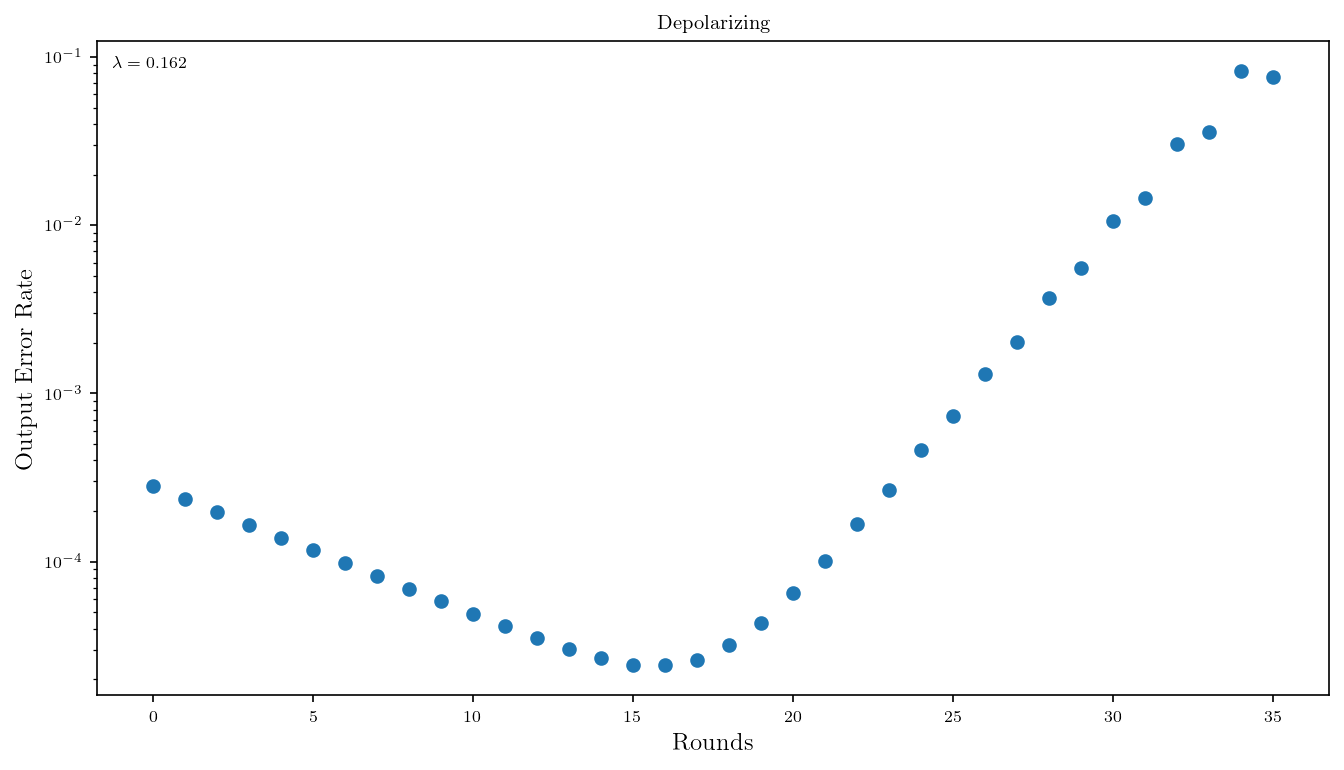

In [11]:
# Exponential fit p_out(r) ~ A exp(-lambda r) on the decreasing branch only.
rounds_arr = np.array([r for r in range(rounds+1)])
output_error_rate = np.asarray(inf_to_error(infidelity_list, 1))

# Fit only the left, decreasing branch
# From your plot this looks roughly like rounds 0 to 16
fit_start = 0
fit_end = 16 # inclusive

mask = (rounds_arr >= fit_start) & (rounds_arr <= fit_end)

x_fit = rounds_arr[mask]
y_fit = output_error_rate[mask]

# Fit log(y) = a r + b
a, b = np.polyfit(x_fit, np.log(y_fit), 1)

lambda_ = -a          # exponential decay parameter
A = np.exp(b)       # prefactor
decay_factor = np.exp(a)  # multiplicative factor per round

print(f"A = {A:.6e}")
print(f"lambda = {lambda_:.6e}")
print(f"per-round decay factor = {decay_factor:.6e}")

# Fitted curve over the fitting region
y_fit_curve = A * np.exp(-lambda_ * x_fit)


plt.figure(figsize=(9, 5))
plt.plot(rounds_arr, output_error_rate, 'o')
plt.xlabel("Rounds", fontsize=12)
plt.ylabel("Output Error Rate", fontsize=12)
plt.yscale('log')
plt.tight_layout()
# Legend with text only
dummy = plt.Line2D([], [], linestyle='none', label=rf'$\lambda={lambda_:.3g}$')
plt.legend(
    handles=[dummy],
    frameon=False,
    loc='upper left',
    handlelength=0,
    handletextpad=0
)
plt.title("Depolarizing")
plt.show()

Multiple input error rates on the same plot

In [18]:
# Main sweep used for the saved data: one trajectory per initial error rate.
# Number of distillation rounds and simulation shots.
rounds = 35
shots = 50
"""
max_input_error = one_qubit_gate_error_prob[4]
min_input_error = max_input_error * 1e-3
num_input_errors = 6

input_error_prob_list1 = np.geomspace(
    max_input_error,
    min_input_error,
    num=num_input_errors,
)
"""
input_error_prob_list1 = np.array([5e-4, 1e-4, 5e-5, 1e-5, 5e-6, 1e-6])

# Alternatively, use exactly the same probabilities as panel (b):
# input_error_prob_list1 = input_error_prob_list2.copy()

rounds_arr1 = np.arange(rounds + 1)

# The backend only needs to be created once.
backend = AerSimulator(method="density_matrix")


def run_depolarizing_distillation(input_error_prob):
    """Run all distillation rounds for one initial error probability."""

    infidelity_list = []

    # Ideal input state.
    prep = (
        ry_theta
        @ np.array([[1], [0]])
        @ np.array([[1, 0]])
        @ ry_theta.conj().T
    )

    # Completely mixed single-qubit state.
    mixed = identity / 2

    # Depolarizing noise.
    rho_in = (
        (1 - input_error_prob) * prep
        + input_error_prob * mixed
    )
    rho_in = DensityMatrix(rho_in / np.trace(rho_in))

    infidelity_list.append(
        1 - state_fidelity(ideal_1q_dm, rho_in)
    )

    for _ in range(rounds):
        rho_two = DensityMatrix(
            np.kron(rho_in.data, rho_in.data)
        )

        meas_circuit = QuantumCircuit(2, 1)

        meas_circuit.append(
            SetDensityMatrix(rho_two),
            meas_circuit.qubits,
        )

        # Two-qubit distillation circuit.
        meas_circuit.cx(0, 1)
        meas_circuit.h(0)

        # Measure qubit 1 and postselect on outcome 0.
        meas_circuit.measure(1, 0)

        meas_circuit.append(
            SaveDensityMatrix(
                num_qubits=2,
                label="dm_post",
                conditional=True,
                pershot=True,
            ),
            meas_circuit.qubits,
        )

        result = backend.run(
            meas_circuit,
            shots=shots,
        ).result()

        conditional_states = result.data()["dm_post"]

        if "0x0" not in conditional_states:
            raise RuntimeError(
                "No postselected outcome 0 was sampled. "
                "Increase shots."
            )

        rho_post_2q = conditional_states["0x0"][0]

        infidelity_list.append(
            1 - state_fidelity(rho_post_2q, ideal_dm)
        )

        # Keep qubit 0 for the next distillation round.
        rho_in = partial_trace(rho_post_2q, [1])

    return np.asarray(
        inf_to_error(infidelity_list, 1)
    )


# Run the simulation for every initial error probability.
output_error_rate_matrix1 = np.stack([
    run_depolarizing_distillation(input_error_prob)
    for input_error_prob in input_error_prob_list1
])

     Input p       Lambda    Decay factor
-------------------------------------------
    5.00e-04     0.170717        0.843060
    1.00e-04     0.174282        0.840060
    5.00e-05     0.174741        0.839675
    1.00e-05     0.175111        0.839364
    5.00e-06     0.175157        0.839325
    1.00e-06     0.175195        0.839293


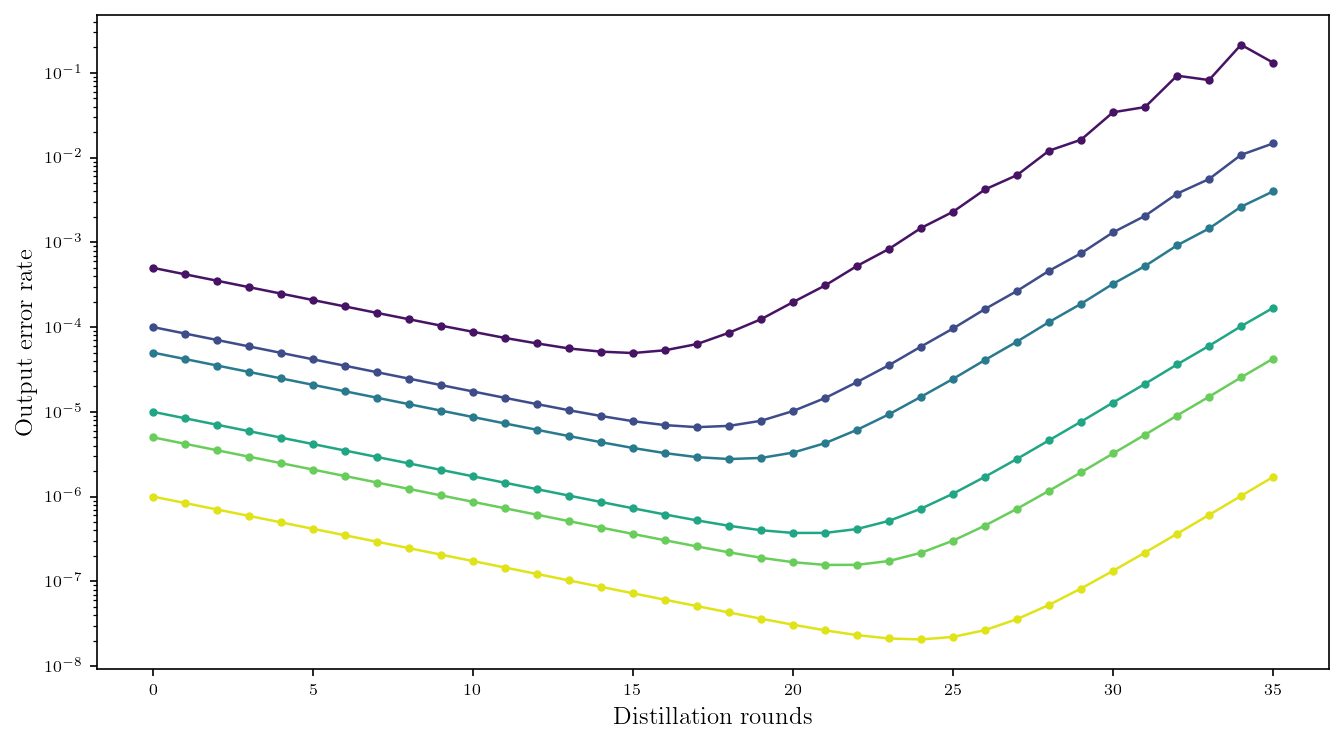

In [19]:
colors = plt.cm.viridis(
    np.linspace(
        0.05,
        0.95,
        len(input_error_prob_list1),
    )
)

plt.figure(figsize=(9, 5))

for output_error_rate, color in zip(
    output_error_rate_matrix1,
    colors,
):
    plt.plot(
        rounds_arr1,
        output_error_rate,
        marker="o",
        markersize=3,
        linewidth=1.2,
        color=color,
    )
    
# Select the fitting interval
fit_start = 0
fit_end = 13

lambda_values = []

print(f"{'Input p':>12} {'Lambda':>12} {'Decay factor':>15}")
print("-" * 43)

for input_error_prob, output_error_rate in zip(
    input_error_prob_list1,
    output_error_rate_matrix1,
):
    # Select valid data in the fitting interval
    fit_mask = (
        (rounds_arr1 >= fit_start)
        & (rounds_arr1 <= fit_end)
        & np.isfinite(output_error_rate)
        & (output_error_rate > 0)
    )

    x_fit = rounds_arr1[fit_mask]
    y_fit = output_error_rate[fit_mask]

    if len(x_fit) >= 3:
        slope, intercept = np.polyfit(
            x_fit,
            np.log(y_fit),
            1,
        )

        lambda_ = -slope
        decay_factor = np.exp(slope)

        lambda_values.append(lambda_)

        print(
            f"{input_error_prob:12.2e} "
            f"{lambda_:12.6f} "
            f"{decay_factor:15.6f}"
        )

    else:
        lambda_values.append(np.nan)
        print(f"{input_error_prob:12.2e}  Insufficient data")

lambda_values = np.array(lambda_values)

plt.xlabel("Distillation rounds", fontsize=12)
plt.ylabel("Output error rate", fontsize=12)
plt.yscale("log")
plt.tight_layout()
plt.show()

# Saving Data

In [20]:
# lambda_value is a hard-coded constant here, not the fit result above.
np.savez_compressed(
    "../../../../data/two_qubit/physical_level/multiple_rounds/depolarizing_error_rates.npz",
    rounds_arr=rounds_arr1,
    input_error_prob_list=input_error_prob_list1,
    output_error_rate_matrix=output_error_rate_matrix1,
    fit_start=fit_start,
    fit_end=fit_end,
    lambda_value=0.1752
)